In [ ]:
import pandas as pd

df = pd.read_csv('data.csv') # 주택 가격 데이터 불러오기
df.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


In [ ]:
df[df['price']==0].head() # 유효한 데이터임에도 불구하고 주택 가격이 0인 경우가 존재
df = df[df['price'] > 0]  # 나중에 최종 예측 모델로 가격 채워넣어 보기

In [ ]:
#df.loc[df['yr_renovated'] == 0, 'yr_renovated'] = df.loc[df['yr_renovated'] == 0, 'yr_built']
# 보수 연도는 0값도 포함하고 있으며, 이를 모델에 직접 넣기에는 적합하지 않으므로
# 보수연도가 0인경우는 지어진 연도로 대체하여 모델 학습에 사용할 것이다

X = df.iloc[:, 2:14] # bedrooms ~ yr_renovated
print(X.columns)
# 침실, 화장실, 주거 면적, 토지 면적, 층수, 해안가 유무, view 평점, 상태 평점, 지상층 면적, 지하층 면적, 지어진 연도, 보수 연도
y = df['price'] # 주택 가격을 종속변수로


Index(['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
       'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement',
       'yr_built', 'yr_renovated'],
      dtype='object')


In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression() # 모델 생성

In [ ]:
from sklearn.model_selection import KFold, cross_val_score # K-Fold 교차검증을 사용하기 위한 모듈 불러오기

kfold = KFold(n_splits=5, shuffle=True, random_state=42) # 객체 생성

scores = cross_val_score(
    model,
    X,
    y,
    cv=kfold,
    scoring='r2'
)

print(list(map(lambda x : float(round(x, 4)), scores)))
print(round(scores.mean(), 4))

[0.6006, 0.0421, 0.261, 0.526, 0.5751]
0.401


In [ ]:
for fold, (train_idx, val_idx) in enumerate(kfold.split(X), 1): # split은 KFold클래스의 메서드 # 학습/검증 인덱스 반환 메서드
    if fold == 2: # fold2
        tidx, vidx = train_idx, val_idx
        fold2_train = df.iloc[train_idx] # fold2의 학습 인덱스에 해당하는 df행 반환
        fold2_val = df.iloc[val_idx] # fold2의 검증 인덱스에 해당하는 df행 반환
        break
fold2_val.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
6,2014-05-02 00:00:00,335000.0,2.0,2.00,1350,2560,1.0,0,0,3,1350,0,1976,0,2616 174th Ave NE,Redmond,WA 98052,USA
7,2014-05-02 00:00:00,482000.0,4.0,2.50,2710,35868,2.0,0,0,3,2710,0,1989,0,23762 SE 253rd Pl,Maple Valley,WA 98038,USA
12,2014-05-02 00:00:00,588500.0,3.0,1.75,2330,14892,1.0,0,0,3,1970,360,1980,0,1833 220th Pl NE,Sammamish,WA 98074,USA
25,2014-05-02 00:00:00,285000.0,3.0,2.50,2090,10834,1.0,0,0,4,1360,730,1987,0,27736 23rd Avenue South,Federal Way,WA 98003,USA


<Axes: ylabel='price'>

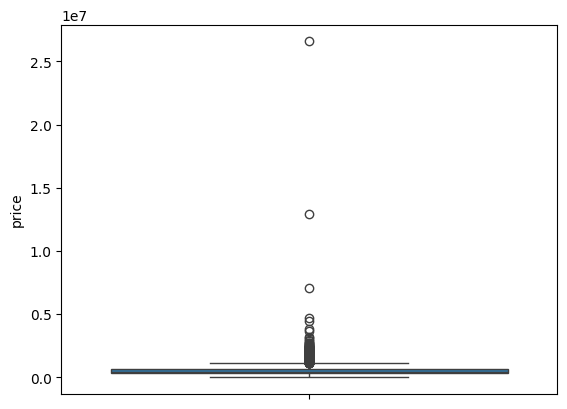

In [ ]:
import seaborn as sns

fold2_all = pd.concat([fold2_train, fold2_val])
sns.boxplot(y=fold2_all['price']) # 이상치가 매우 많이 나옴

<Axes: ylabel='price'>

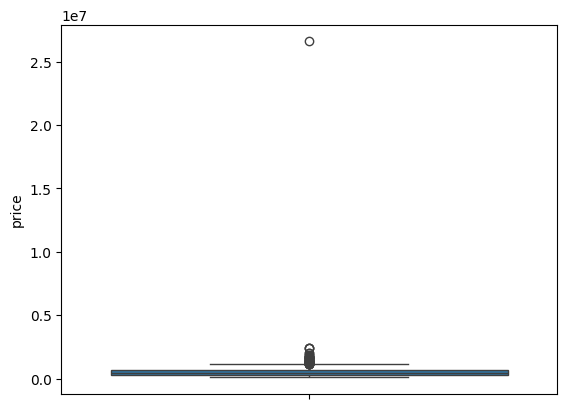

In [ ]:
sns.boxplot(y=fold2_val['price'])

<Axes: ylabel='price'>

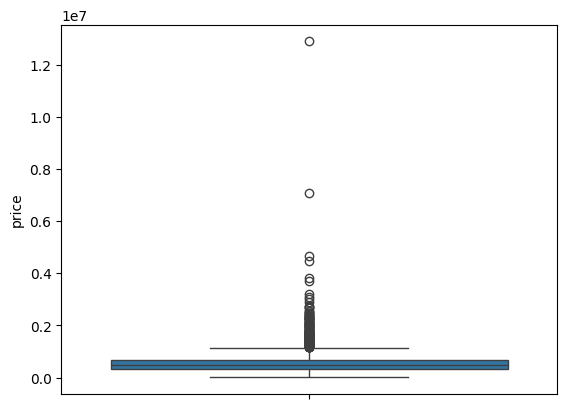

In [ ]:
sns.boxplot(y=fold2_train['price'])

In [ ]:
fold2_all['price'].sort_values(ascending=False).head(10) # fold2의 상위 10가격 값들

,price
4350,26590000.0
4346,12899000.0
2286,7062500.0
2654,4668000.0
2761,4489000.0
3729,3800000.0
1637,3710000.0
252,3200000.0
1567,3100000.0
2772,3000000.0


In [ ]:
df['price'].sort_values(ascending=False).head(10)

,price
4350,26590000.0
4346,12899000.0
2286,7062500.0
2654,4668000.0
2761,4489000.0
3729,3800000.0
1637,3710000.0
252,3200000.0
1567,3100000.0
2772,3000000.0


In [ ]:
print(float(fold2_all['price'].mean()), fold2_all['price'].median())
print(float(fold2_val['price'].mean()), fold2_val['price'].median())
print(float(fold2_train['price'].mean()), fold2_train['price'].median())

557905.8991379444 465000.0
570450.4872000022 466500.0
554770.6134646479 465000.0


In [ ]:
newmodel = LinearRegression()
newmodel.fit(X.iloc[tidx], y.iloc[tidx])
pred = newmodel.predict(X.iloc[vidx])

fold2_r = df.iloc[val_idx][['price']].copy()
fold2_r['pred'] = pred
fold2_r['pred'] = fold2_r['pred'].apply(lambda x:round(x, 2))
fold2_r['diff'] = abs(fold2_r['price'] - fold2_r['pred'])

fold2_r.sort_values('price', ascending=False).head(10)


,price,pred,diff
4350,26590000.0,217138.03,26372861.97
1543,2453500.0,1441430.35,1012069.65
2980,2400000.0,1546434.29,853565.71
1600,2400000.0,1126669.26,1273330.74
839,2000000.0,1868871.48,131128.52
3496,1990000.0,1410115.17,579884.83
564,1895000.0,766053.15,1128946.85
217,1870000.0,1261201.11,608798.89
1974,1800000.0,1115737.02,684262.98
3964,1738000.0,847431.67,890568.33


In [ ]:
fold2_r.sort_values('diff', ascending=False).head(10)

,price,pred,diff
4350,26590000.0,217138.03,26372861.97
1600,2400000.0,1126669.26,1273330.74
564,1895000.0,766053.15,1128946.85
1163,503000.0,1543562.56,1040562.56
1543,2453500.0,1441430.35,1012069.65
3935,1625000.0,727485.03,897514.97
3964,1738000.0,847431.67,890568.33
2980,2400000.0,1546434.29,853565.71
3195,549000.0,1348745.20,799745.20
2480,849900.0,92303.21,757596.79


In [ ]:
for seed in [41, 42, 43, 44, 45]: # 42시드에서만 치우친 결과가 나오는 지를 확인하기 위해 여러 시드와
  for k in [3, 4, 5, 6, 7, 8, 9, 10]: # 여러 k값으로 교차검증
      kfold = KFold(
          n_splits=k,
          shuffle=True,
          random_state=seed
      )

      scores = cross_val_score(
          model,
          X,
          y,
          cv=kfold,
          scoring='r2'
      )

      print(seed, k)
      print(scores)
      print(scores.mean())
      print('min :', scores.min())
      print('-------------------------------------------------------------------------------')


41 3
[0.56236098 0.08959667 0.58539035]
0.41244933428647973
min : 0.08959667478135702
-------------------------------------------------------------------------------
41 4
[0.5514711  0.29266043 0.10573456 0.49153393]
0.36035000791766053
min : 0.10573456312152829
-------------------------------------------------------------------------------
41 5
[0.54608787 0.59163117 0.25609036 0.0807469  0.4828591 ]
0.39148308206651067
min : 0.08074690322405642
-------------------------------------------------------------------------------
41 6
[0.54452029 0.58405078 0.23458497 0.04206997 0.6279741  0.52076601]
0.42566101839825493
min : 0.04206996882303382
-------------------------------------------------------------------------------
41 7
[0.54821486 0.54891372 0.6086693  0.22984072 0.03518847 0.63218173
 0.48909767]
0.44172949541046475
min : 0.035188465281983605
-------------------------------------------------------------------------------
41 8
[0.56389566 0.53002844 0.61263536 0.17908816 0.548484

In [ ]:
# fold2에서 나온 극단값 제거후 모델 새로 작성

testdf = df[df['price'] != 26590000] # fold2에서 나온 극단값(하나만) 제거
#print(testdf.max())
newX = testdf.iloc[:, 2:14]
newy = testdf['price']

newmodel = LinearRegression()


In [ ]:
from sklearn.model_selection import KFold, cross_val_score

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    newmodel,
    newX,
    newy,
    cv=kfold,
    scoring='r2'
)
print(list(map(lambda x : float(round(x, 4)), scores)))
print(round(scores.mean(), 4))
print('min :', scores.min())
print('-------------------------------------------------------------------------------')


[0.299, 0.527, 0.5768, 0.5322, 0.5745]
0.5019
min : 0.29902549096546127
-------------------------------------------------------------------------------


In [ ]:
for fold, (train_idx, val_idx) in enumerate(kfold.split(newX), 1):
    if fold == 2:
      newfold2_val = testdf.iloc[val_idx]
      newfold2_train = testdf.iloc[train_idx]
      break
newfold2_all = pd.concat([newfold2_train, newfold2_val])

<Axes: ylabel='price'>

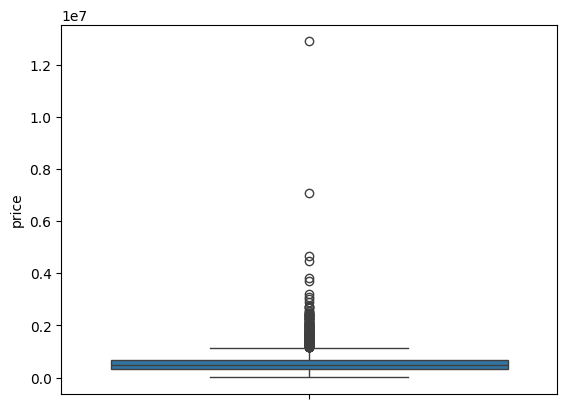

In [ ]:
import seaborn as sns

sns.boxplot(y=newfold2_all['price'])

In [ ]:
# 채우기
df_fi = pd.read_csv('data.csv')
zeroindx = df_fi[df_fi['price'] == 0].index
model.fit(X, y)
df_fi.loc[df_fi["price"] == 0, "price"] = model.predict(
    df_fi.loc[df_fi["price"] == 0, X.columns]
)

In [56]:
df_fi.loc[zeroindx]

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
4354,2014-05-05 00:00:00,4.010399e+05,3.0,1.75,1490,10125,1.0,0,0,4,1490,0,1962,0,3911 S 328th St,Federal Way,WA 98001,USA
4356,2014-05-05 00:00:00,6.809441e+05,4.0,2.75,2600,5390,1.0,0,0,4,1300,1300,1960,2001,2120 31st Ave W,Seattle,WA 98199,USA
4357,2014-05-05 00:00:00,8.290072e+05,6.0,2.75,3200,9200,1.0,0,2,4,1600,1600,1953,1983,12271 Marine View Dr SW,Burien,WA 98146,USA
4358,2014-05-06 00:00:00,8.593535e+05,5.0,3.50,3480,36615,2.0,0,0,4,2490,990,1983,0,21809 SE 38th Pl,Issaquah,WA 98075,USA
4361,2014-05-07 00:00:00,3.766077e+05,5.0,1.50,1500,7112,1.0,0,0,5,760,740,1920,0,14901-14999 12th Ave SW,Burien,WA 98166,USA
4362,2014-05-07 00:00:00,1.024599e+06,4.0,4.00,3680,18804,2.0,0,0,3,3680,0,1990,2009,1223-1237 244th Ave NE,Sammamish,WA 98074,USA
4374,2014-05-09 00:00:00,5.809127e+05,2.0,2.50,2200,188200,1.0,0,3,3,2200,0,2007,0,39612 254th Ave SE,Enumclaw,WA 98022,USA
4376,2014-05-09 00:00:00,6.459338e+05,4.0,2.25,2170,10500,1.0,0,2,4,1270,900,1960,2001,216 SW 183rd St,Normandy Park,WA 98166,USA
4382,2014-05-12 00:00:00,1.154186e+06,5.0,4.50,4630,6324,2.0,0,0,3,3210,1420,2006,0,6925 Oakmont Ave SE,Snoqualmie,WA 98065,USA
4383,2014-05-13 00:00:00,1.117053e+06,5.0,4.00,4430,9000,2.0,0,0,3,4430,0,2013,1923,9235 NE 5th St,Bellevue,WA 98004,USA


In [57]:
print(X.columns)

Index(['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
       'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement',
       'yr_built', 'yr_renovated'],
      dtype='object')


In [58]:
print(df_fi.columns)

Index(['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
       'floors', 'waterfront', 'view', 'condition', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city',
       'statezip', 'country'],
      dtype='object')
